# Tropical-cyclone intensity verification

This notebook reads ATCF A-deck forecasts and B-deck best-track data from the repository's `data/adeck` and `data/bdeck` directories. It verifies `VMAX`, `PMIN`, `RMW`, `R34`, `R50`, or `R64` using either strict or lead-dependent relaxed sampling.

In `strict` mode, a cycle is retained only when the B-deck contains `cycle + lead_time` and every requested model and the best track have a valid selected metric at every verified lead. In `relaxed` mode, complete common cases are selected independently at each lead and the returned `n_cases` reports the changing sample size. Errors are forecast minus best track. To match the requested `T = int(lead_time / hh)`, the verified leads are `0, hh, ..., (T-1) * hh`. Correlation is the Pearson correlation over all valid forecast/best-track pairs for each model.

For wind-radius metrics, an `AAA` record uses its single radius. Other wind-code records use the arithmetic mean of the four quadrant radii; explicit zero radii are included. Intensity is in kt (`VMAX`), pressure in hPa (`PMIN`), and radii in nautical miles (`RMW`, `R34`, `R50`, and `R64`).

In [1]:
from __future__ import annotations

from typing import Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np

try:
    from src import mod_abdeck as abdeck
    from src import mod_verification as verif
except ModuleNotFoundError as exc:
    if exc.name != "src":
        raise
    import mod_abdeck as abdeck
    import mod_verification as verif

## Find the first B-deck threshold period

For `VMAX`, `RMW`, `R34`, `R50`, and `R64`, a cycle qualifies when the metric is strictly greater than the threshold. For `PMIN`, the comparison is reversed and a cycle qualifies when pressure is strictly less than the threshold. The returned interval is `[start_cycle, end_cycle)`, so `end_cycle` is the first non-qualifying cycle and is not part of the qualifying period.

In [2]:
threshold_metric = "VMAX"
threshold_value = 95
threshold_start_cycle, threshold_end_cycle = abdeck.find_bdeck_threshold_period(
    storm_id="17E",
    year="2026",
    metric=threshold_metric,
    threshold=threshold_value,
)

qualifying_operator = "<" if threshold_metric == "PMIN" else ">"
ending_operator = ">=" if threshold_metric == "PMIN" else "<="
print(
    f"First {threshold_metric} {qualifying_operator} {threshold_value} cycle:",
    threshold_start_cycle,
)
print(
    f"First following {threshold_metric} {ending_operator} {threshold_value} cycle "
    "(exclusive end):",
    threshold_end_cycle,
)

# For PMIN, try threshold_metric="PMIN" and threshold_value=970.
# The function will select PMIN < 970 and stop at the first PMIN >= 970.

First VMAX > 95 cycle: 2026092206
First following VMAX <= 95 cycle (exclusive end): 2026092906


In [3]:
def plot_verification_errors(
    errs_abs: Sequence[Sequence[float]],
    errs_bias: Sequence[Sequence[float]],
    models: Sequence[str],
    hh: int,
    metric: str,
    *,
    n_cases: Sequence[int] | None = None,
    figsize: Tuple[float, float] = (12, 4.5),
) -> Tuple[plt.Figure, np.ndarray]:
    if len(models) != len(errs_abs) or len(models) != len(errs_bias):
        raise ValueError("models, errs_abs, and errs_bias must have equal lengths.")
    if not models:
        raise ValueError("At least one model is required.")
    if isinstance(hh, bool) or not isinstance(hh, int) or hh <= 0:
        raise ValueError("hh must be a positive integer.")

    n_leads = len(errs_abs[0])
    if any(len(values) != n_leads for values in list(errs_abs) + list(errs_bias)):
        raise ValueError("All error series must have the same number of leads.")
    if n_cases is not None and len(n_cases) != n_leads:
        raise ValueError("n_cases must have one value per forecast lead.")
    lead_hours = np.arange(n_leads) * hh
    units = {
        "VMAX": "VMAX (kt)",
        "PMIN": "hPa",
        "RMW": "n mi",
        "R34": "n mi",
        "R50": "n mi",
        "R64": "n mi",
    }
    metric = str(metric).strip().upper()
    unit = units.get(metric, "metric units")

    fig, axes = plt.subplots(1, 2, figsize=figsize, sharex=True)
    for model, mae, bias in zip(models, errs_abs, errs_bias):
        axes[0].plot(lead_hours, mae, marker="o", label=model)
        axes[1].plot(lead_hours, bias, marker="o", label=model)

    axes[0].set_title(f"{metric} mean absolute error")
    axes[1].set_title(f"{metric} bias (forecast - best track)")
    axes[0].set_ylabel(unit,fontsize=16)
    axes[0].set_xlim([0,72.5])
    axes[0].set_ylim([0,19.8])
    axes[0].set_yticks([0, 5, 10, 15, 20])
    axes[1].set_yticks([-15, -10, -5, 0, 5])
    axes[0].tick_params(axis='x', labelsize=14) 
    axes[0].tick_params(axis='y', labelsize=14) 
    axes[1].tick_params(axis='x', labelsize=14) 
    axes[1].tick_params(axis='y', labelsize=14) 
    axes[1].axhline(0.0, color="black", linewidth=0.8)
    axes[0].legend(fontsize=14)
    for axis in axes:
        if n_cases is None:
            axis.set_xticks([0, 6, 12, 18, 24, 36, 48, 72])            
            axis.set_xlim(0, 72.5)
        else:
            axis.set_xticks(lead_hours)
            axis.set_xticklabels(
                [f"{lead}\n{count}" for lead, count in zip(lead_hours, n_cases)],
                fontsize=12,
            )
            axis.set_xlim(lead_hours[0] - hh / 2, lead_hours[-1] + hh / 2)
        axis.set_xlabel("Forecast lead time (h)",fontsize=16)
        axis.grid(True, alpha=0.3)        
    fig.tight_layout()
    return fig, axes

## Check a single storm verification

Choose a storm, time interval, model identifiers, and sampling mode. Set `end_cycle=None` to use every common cycle on or after `start_cycle`. In relaxed mode, the second row of each x-axis tick label is the number of verified cases.

Cycles represented in errs (N): 12
Lead count (T): 20
Verified cases by lead: {0: 12, 6: 12, 12: 12, 18: 12, 24: 12, 30: 12, 36: 12, 42: 12, 48: 12, 54: 12, 60: 12, 66: 12, 72: 12, 78: 12, 84: 12, 90: 12, 96: 12, 102: 12, 108: 12, 114: 12}
Correlations: {'HWRF': 0.7260372534014379, 'HFSA': 0.6946278019854335}


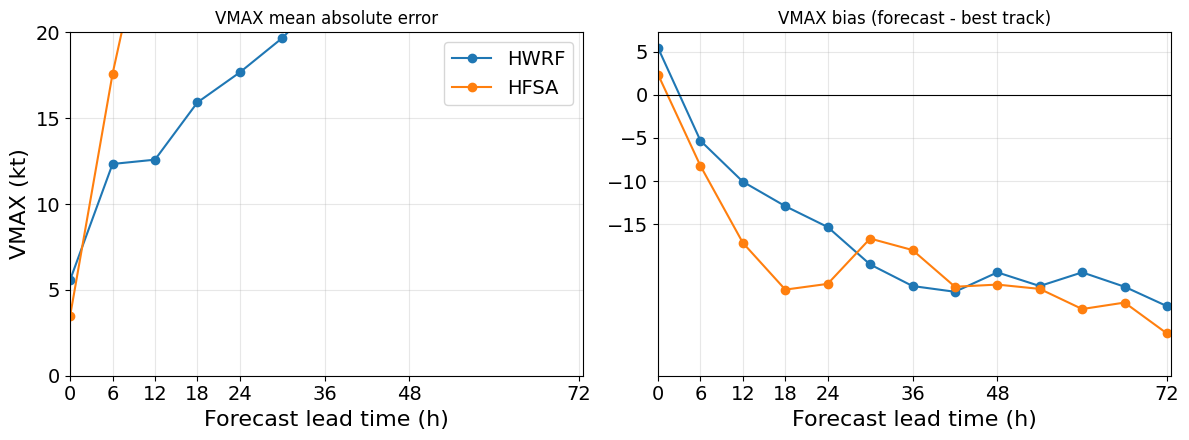

In [4]:
# Example (edit these values for the desired storm):
models = ["HWRF", "HFSA"]
hh = 6
sample_mode = "strict"  # Change to "relaxed" for per-lead samples.
errs, errs_abs, errs_bias, corr, n_cases = verif.verify_single_storm(
    storm_id="17E",
    year="2026",
    start_cycle="2026092206",
    end_cycle="2026092500",
    models=models,
    hh=hh,
    lead_time=120,
    metric="VMAX",
    sample_mode=sample_mode,
)

print("Cycles represented in errs (N):", errs[0].shape[0])
print("Lead count (T):", errs[0].shape[1])
lead_hours = (np.arange(len(n_cases)) * hh).tolist()
print("Verified cases by lead:", dict(zip(lead_hours, n_cases)))
print("Correlations:", dict(zip(models, corr)))
fig, axes = plot_verification_errors(
    errs_abs,
    errs_bias,
    models,
    hh,
    "VMAX",
    n_cases=n_cases if sample_mode == "relaxed" else None,
)

## Check a multiple-storm verification

Each filename identifies an A-deck and its matching B-deck. For each storm, the function uses `find_bdeck_threshold_period` to select the first contiguous threshold period, then calls `verify_single_storm`. MAE and bias pool all finite cases at each lead; correlation is the arithmetic mean of the finite per-storm correlations for each model. Storms that never meet the threshold are skipped.

Storm files: ['aep112026.dat', 'aep122026.dat', 'aep192026.dat', 'aep152026.dat', 'aep172026.dat', 'aep072026.dat', 'aep112025.dat', 'awp042026.dat', 'awp092026.dat', 'awp122026.dat', 'awp242025.dat', 'awp302025.dat', 'awp062023.dat', 'awp092023.dat', 'aal082025.dat', 'aal132025.dat', 'aal022024.dat', 'aal122024.dat', 'aal072022.dat']
Verified cases by lead: {0: 116, 6: 116, 12: 116, 18: 116, 24: 116, 30: 116, 36: 116, 42: 116, 48: 116, 54: 116, 60: 116, 66: 116, 72: 116}
Mean per-storm correlations: {'HWRF': 0.7768455034703303, 'HFSA': 0.8023047397471903, 'CTCX': 0.7811416370650124, 'HFSB': 0.817834981491995, 'HMON': 0.8215709672290373}


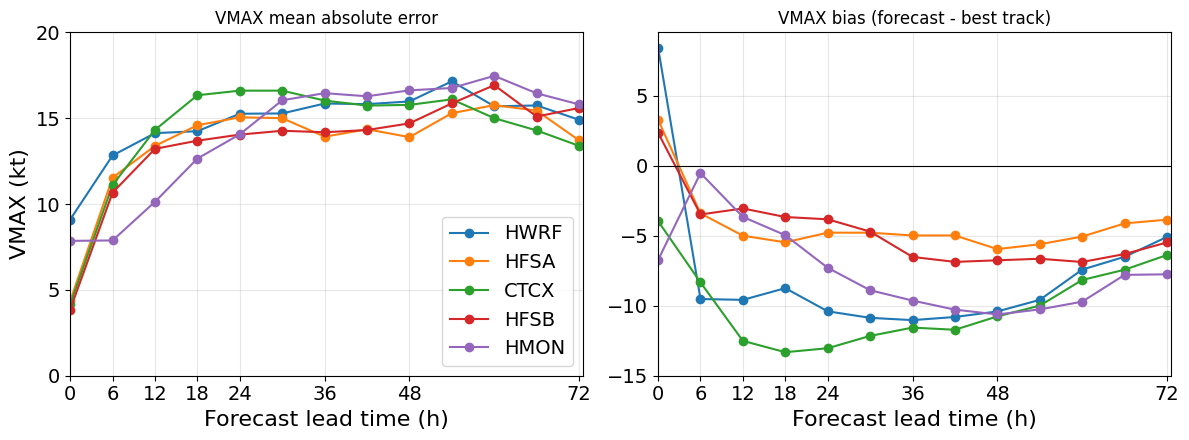

In [5]:
multiple_storms = [
          "aep112026.dat", "aep122026.dat", "aep192026.dat", "aep152026.dat", "aep172026.dat", "aep072026.dat", "aep112025.dat",
          "awp042026.dat", "awp092026.dat", "awp122026.dat", "awp242025.dat", "awp302025.dat", "awp062023.dat", "awp092023.dat",
          "aal082025.dat", "aal132025.dat", "aal022024.dat", "aal122024.dat", "aal072022.dat",]
multiple_threshold = 95
models = ["HWRF", "HFSA", "CTCX", "HFSB", "HMON"]
multiple_metric = "VMAX"
multiple_errs_abs, multiple_errs_bias, multiple_corr, multiple_n_cases = (
    verif.verify_multiple_storm(
        storms=multiple_storms,
        threshold=multiple_threshold,
        metric=multiple_metric,
        models=models,
        hh=hh,
        lead_time=78,
        sample_mode=sample_mode,
    )
)

multiple_lead_hours = (np.arange(len(multiple_n_cases)) * hh).tolist()
print("Storm files:", multiple_storms)
print("Verified cases by lead:", dict(zip(multiple_lead_hours, multiple_n_cases)))
print("Mean per-storm correlations:", dict(zip(models, multiple_corr)))
multiple_fig, multiple_axes = plot_verification_errors(
    multiple_errs_abs,
    multiple_errs_bias,
    models,
    hh,
    multiple_metric,
    n_cases=multiple_n_cases if sample_mode == "relaxed" else None,
)

## Mean intensity-change correlation in two VMAX ranges

Cycles are classified by B-deck VMAX at initialization. The left group uses `threshold_value_1 < VMAX < threshold_value_2`; the right group uses `threshold_value_3 < VMAX < threshold_value_4`. For every cycle, consecutive forecast and B-deck changes are formed over 0--`hh`, `hh`--2`hh`, ..., through `correlation_lead_time`. One correlation is calculated from those change pairs for each model and cycle. Each bar is the mean of the finite cycle correlations from all storms, and each error bar is one population standard deviation across those cycles. All range bounds are exclusive. With only two change intervals, every defined cycle correlation is necessarily -1 or +1, so a longer correlation window is normally more informative.

35 < VMAX < 95
  HWRF: mean=0.224, SD=0.252, N_cycles=112
  HFSA: mean=0.240, SD=0.220, N_cycles=112
  CTCX: mean=0.226, SD=0.242, N_cycles=112
  HFSB: mean=0.293, SD=0.195, N_cycles=112
  HMON: mean=0.233, SD=0.246, N_cycles=112
100 < VMAX < 200
  HWRF: mean=0.035, SD=0.287, N_cycles=62
  HFSA: mean=0.162, SD=0.285, N_cycles=62
  CTCX: mean=0.107, SD=0.291, N_cycles=62
  HFSB: mean=0.171, SD=0.277, N_cycles=62
  HMON: mean=0.111, SD=0.252, N_cycles=62


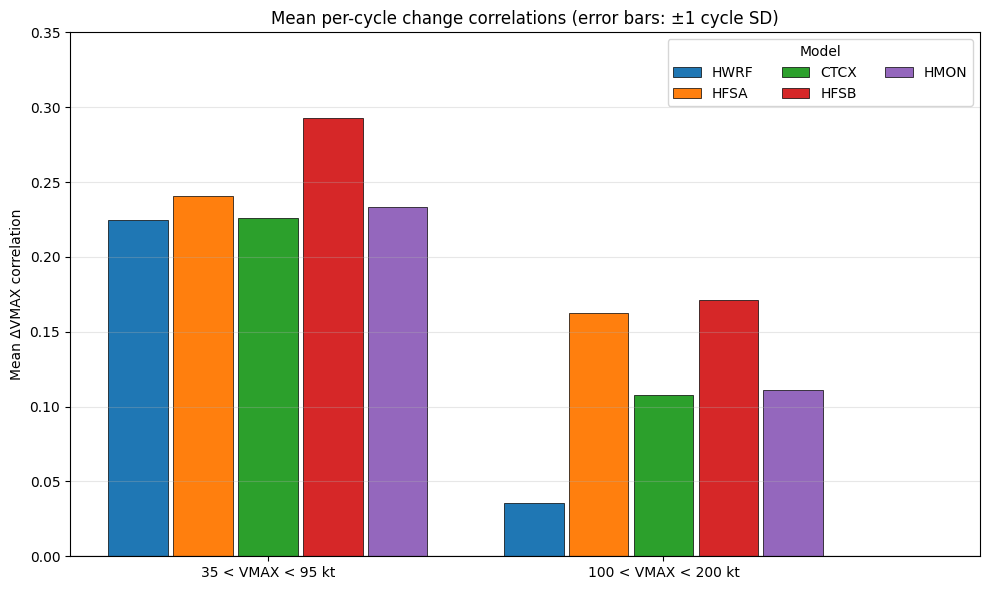

In [16]:
threshold_value_1 = 35
threshold_value_2 = 95
threshold_value_3 = 100
threshold_value_4 = 200
correlation_metric = "VMAX"
correlation_lead_time = 120

mean_corr, corr_std, corr_n_cycles = (
    verif.compute_threshold_correlation_statistics(
        storms=multiple_storms,
        models=models,
        metric=correlation_metric,
        threshold_value_1=threshold_value_1,
        threshold_value_2=threshold_value_2,
        threshold_value_3=threshold_value_3,
        threshold_value_4=threshold_value_4,
        hh=hh,
        lead_time=correlation_lead_time,
        sample_mode=sample_mode,
    )
)

group_positions = np.arange(2, dtype=float)
group_width = 0.82
bar_width = group_width / len(models)
model_colors = plt.get_cmap("tab10").colors
correlation_fig, correlation_ax = plt.subplots(figsize=(10, 6))
for model_index, model in enumerate(models):
    offset = (model_index - (len(models) - 1) / 2) * bar_width
    values = [mean_corr[0][model_index], mean_corr[1][model_index]]
    errors = [corr_std[0][model_index], corr_std[1][model_index]]
    correlation_ax.bar(
        group_positions + offset,
        values,
        width=bar_width * 0.92,
        #yerr=errors,
        capsize=4,
        color=model_colors[model_index % len(model_colors)],
        edgecolor="black",
        linewidth=0.5,
        label=model,
    )

correlation_ax.set_xticks(group_positions)
correlation_ax.set_xticklabels(
    [
        f"{threshold_value_1:g} < VMAX < {threshold_value_2:g} kt",
        f"{threshold_value_3:g} < VMAX < {threshold_value_4:g} kt",
    ]
)
correlation_ax.set_ylabel(f"Mean Δ{correlation_metric} correlation")
correlation_ax.set_title(
    "Mean per-cycle change correlations (error bars: ±1 cycle SD)"
)
correlation_ax.set_xlim(-0.5, 1.8)
correlation_ax.set_ylim(0, 0.35)
correlation_ax.axhline(0.0, color="black", linewidth=0.8)
correlation_ax.grid(axis="y", alpha=0.3)
correlation_ax.legend(title="Model", ncol=min(len(models), 3))
correlation_fig.tight_layout()

for group_label, means, errors, counts in zip(
    [
        f"{threshold_value_1:g} < VMAX < {threshold_value_2:g}",
        f"{threshold_value_3:g} < VMAX < {threshold_value_4:g}",
    ],
    mean_corr,
    corr_std,
    corr_n_cycles):
    
    print(group_label)
    for model, mean_value, error_value, count in zip(models, means, errors, counts):
        print(
            f"  {model}: mean={mean_value:.3f}, "
            f"SD={error_value:.3f}, N_cycles={count}"
        )